## Exploratory Data Analysis (EDA)

We will start by loading the dataset `/content/Cola (1).xlsx`, examining its structure, checking for missing values, and performing initial descriptive statistics.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

file_path = '/content/Cola (1).xlsx'
df = pd.read_excel(file_path)

print("Dataset Info")
display(df.info())

print("First 5 Rows")
display(df.head())

print("Summary Statistics")
display(df.describe(include='all'))

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Data provided by SimFin  3 non-null      object
 1   Unnamed: 1               97 non-null     object
 2   Unnamed: 2               82 non-null     object
 3   Unnamed: 3               82 non-null     object
 4   Unnamed: 4               82 non-null     object
 5   Unnamed: 5               82 non-null     object
 6   Unnamed: 6               82 non-null     object
 7   Unnamed: 7               82 non-null     object
 8   Unnamed: 8               90 non-null     object
 9   Unnamed: 9               92 non-null     object
 10  Unnamed: 10              93 non-null     object
 11  Unnamed: 11              93 non-null     object
dtypes: object(12)
memory usage: 9.8+ KB


None


--- First 5 Rows ---


,Data provided by SimFin,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Profit & Loss statement,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,in million USD,FY '09,FY '10,FY '11,FY '12,FY '13,FY '14,FY '15,FY '16,FY '17,FY '18
3,NaN,NET OPERATING REVENUES,30990,35119,46542,48017,46854,45998,44294,41863,35410,31856
4,NaN,Cost of goods sold,11088,12693,18215,19053,18421,17889,17482,16465,13255,11770



--- Summary Statistics ---


,Data provided by SimFin,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11
count,3,97,82,82,82,82,82,82,90,92,93,93
unique,3,90,77,77,77,77,77,78,79,78,87,86
top,Profit & Loss statement,in million USD,FY '09,FY '10,FY '11,FY '12,FY '13,FY '14,0,0,FY '17,FY '18
freq,1,3,3,3,3,3,3,3,6,8,3,3


### Data Cleansing & Missing Values Analysis

Let's check for any missing values across columns and handle them accordingly.

In [ ]:
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

num_cols = df.select_dtypes(include=['number']).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"\nNumerical Columns: {num_cols}")
print(f"Categorical Columns: {cat_cols}")

Missing values per column:
Data provided by SimFin    100
Unnamed: 1                   6
Unnamed: 2                  21
Unnamed: 3                  21
Unnamed: 4                  21
Unnamed: 5                  21
Unnamed: 6                  21
Unnamed: 7                  21
Unnamed: 8                  13
Unnamed: 9                  11
Unnamed: 10                 10
Unnamed: 11                 10
dtype: int64

Numerical Columns: []
Categorical Columns: ['Data provided by SimFin', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']


### Visualizations

We will now generate visualizations based on the available columns. This includes plotting distributions of numerical variables and correlation heatmaps to understand how features interact.

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

if len(num_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap')
    plt.tight_layout()
    plt.show()

### Categorical Variables Analysis

Let's examine the distributions of categorical columns to understand the composition of the dataset.

/tmp/ipykernel_2200/1001000726.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')


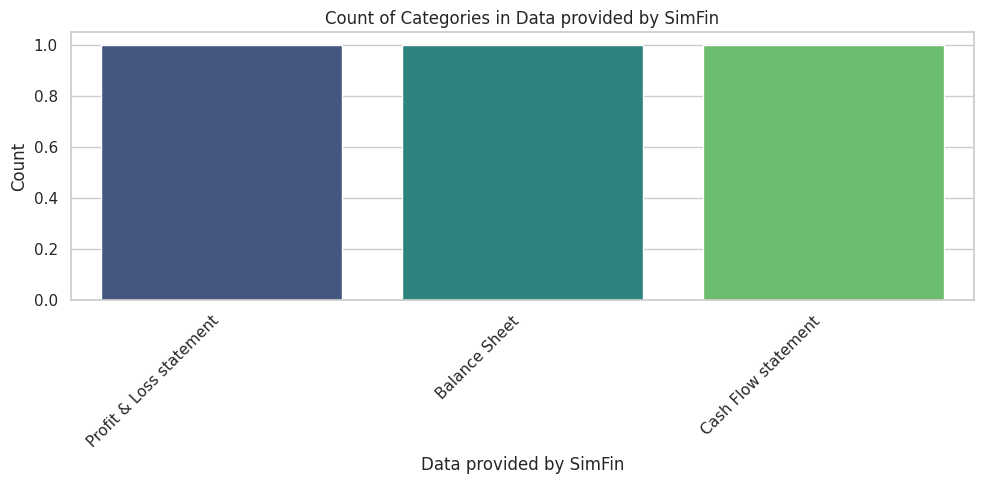

Column 'Unnamed: 1' has 90 unique categories. Showing top 10:
Unnamed: 1
in million USD                           3
Other operating charges                  2
Net income from continuing operations    2
CONSOLIDATED NET INCOME                  2
Deferred income taxes                    2
Assets held for sale                     2
Operating Income                         1
Interest income                          1
NET OPERATING REVENUES                   1
Cost of goods sold                       1
Name: count, dtype: int64
Column 'Unnamed: 2' has 77 unique categories. Showing top 10:
Unnamed: 2
FY '09    3
48671     2
0         2
6906      2
30990     1
313       1
8231      1
249       1
355       1
781       1
Name: count, dtype: int64
Column 'Unnamed: 3' has 77 unique categories. Showing top 10:
Unnamed: 3
FY '10    3
50        2
72921     2
11837     2
35119     1
819       1
8413      1
317       1
733       1
1025      1
Name: count, dtype: int64
Column 'Unnamed: 4' has 77 unique

In [ ]:
for col in cat_cols:
    if df[col].nunique() <= 15:
        plt.figure(figsize=(10, 5))
        sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='viridis')
        plt.title(f'Count of Categories in {col}')
        plt.xticks(rotation=45, ha='right')
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.tight_layout()
        plt.show()
    else:
        print(f"Column '{col}' has {df[col].nunique()} unique categories. Showing top 10:")
        print(df[col].value_counts().head(10))

## Financial Statement Restructuring and Trend Analysis

Since the data consists of unstructured rows representing financial metrics where columns `Unnamed: 2` through `Unnamed: 11` represent years from FY '09 to FY '18, we will locate key rows (like `NET OPERATING REVENUES`, `Cost of goods sold`, and `CONSOLIDATED NET INCOME`), clean their values, and plot their trends over time.

--- Cleaned Financial Trends (Values in Million USD) ---


,Year,NET OPERATING REVENUES,Cost of goods sold,CONSOLIDATED NET INCOME
0,FY '09,30990,11088,6906
1,FY '10,35119,12693,11837
2,FY '11,46542,18215,8646
3,FY '12,48017,19053,9086
4,FY '13,46854,18421,8626
5,FY '14,45998,17889,7124
6,FY '15,44294,17482,7366
7,FY '16,41863,16465,6550
8,FY '17,35410,13255,1283
9,FY '18,31856,11770,6476


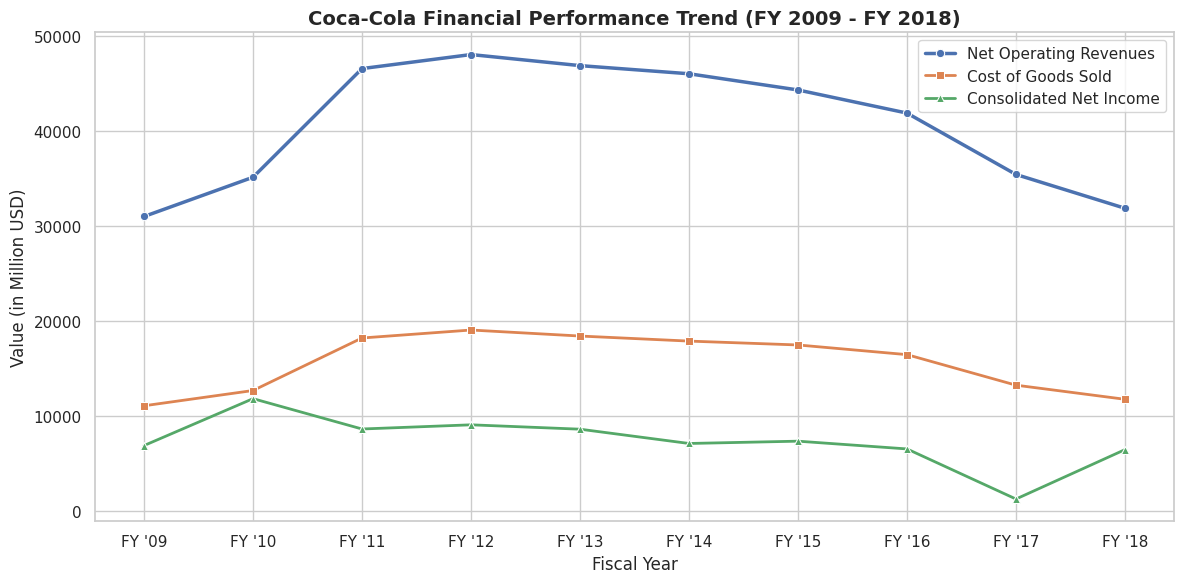

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/Cola (1).xlsx'
df_raw = pd.read_excel(file_path)

df_raw['Unnamed: 1'] = df_raw['Unnamed: 1'].astype(str).str.strip()

target_metrics = ['NET OPERATING REVENUES', 'Cost of goods sold', 'Gross profit', 'CONSOLIDATED NET INCOME']

year_cols = df_raw.iloc[2, 2:12].values
year_cols = [str(y).strip() for y in year_cols]

trend_data = {}
for metric in target_metrics:
    row = df_raw[df_raw['Unnamed: 1'] == metric]
    if not row.empty:

        values = pd.to_numeric(row.iloc[0, 2:12].values, errors='coerce')
        trend_data[metric] = values
df_trends = pd.DataFrame(trend_data, index=year_cols).reset_index()
df_trends.rename(columns={'index': 'Year'}, inplace=True)

print("--- Cleaned Financial Trends (Values in Million USD) ---")
display(df_trends)

#
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_trends, x='Year', y='NET OPERATING REVENUES', marker='o', label='Net Operating Revenues', linewidth=2.5)
sns.lineplot(data=df_trends, x='Year', y='Cost of goods sold', marker='s', label='Cost of Goods Sold', linewidth=2)
sns.lineplot(data=df_trends, x='Year', y='CONSOLIDATED NET INCOME', marker='^', label='Consolidated Net Income', linewidth=2)

plt.title('Coca-Cola Financial Performance Trend (FY 2009 - FY 2018)', fontsize=14, fontweight='bold')
plt.ylabel('Value (in Million USD)', fontsize=12)
plt.xlabel('Fiscal Year', fontsize=12)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

### Gross Profit Margin & Net Profit Margin Analysis
Let's calculate and plot the percentage margins over time to assess financial efficiency.

--- Financial Margin Percentages ---


,Year,Gross Margin (%),Net Margin (%)
0,FY '09,64.220716,22.284608
1,FY '10,63.857171,33.705402
2,FY '11,60.863306,18.576769
3,FY '12,60.320303,18.922465
4,FY '13,60.684253,18.410381
5,FY '14,61.109179,15.487630
6,FY '15,60.531900,16.629792
7,FY '16,60.669326,15.646275
8,FY '17,62.567071,3.623270
9,FY '18,63.052486,20.328980


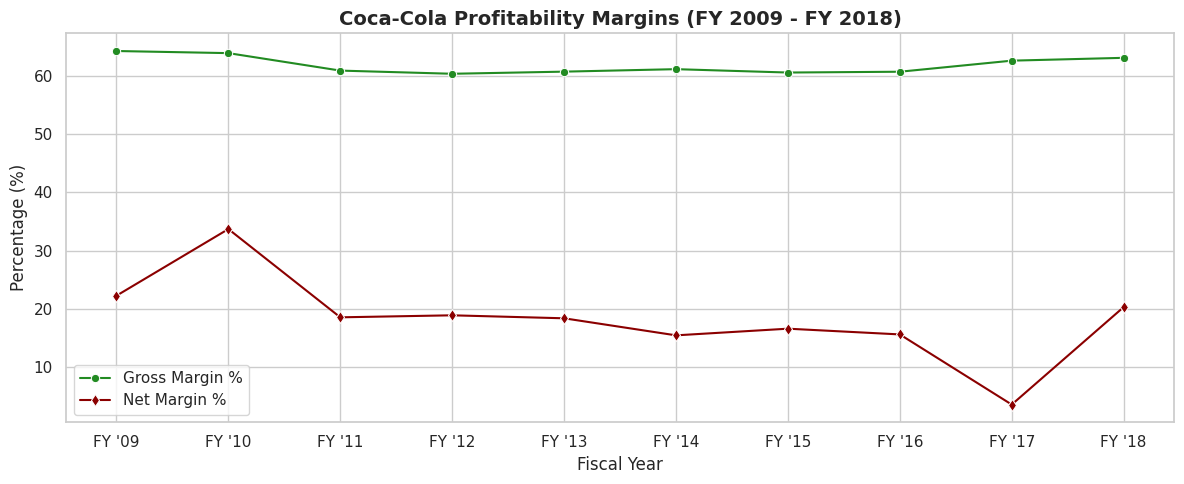

In [ ]:
df_trends['Gross profit'] = df_trends['NET OPERATING REVENUES'] - df_trends['Cost of goods sold']

df_trends['Gross Margin (%)'] = (df_trends['Gross profit'] / df_trends['NET OPERATING REVENUES']) * 100
df_trends['Net Margin (%)'] = (df_trends['CONSOLIDATED NET INCOME'] / df_trends['NET OPERATING REVENUES']) * 100

print("Financial Margin Percentages")
display(df_trends[['Year', 'Gross Margin (%)', 'Net Margin (%)']])

plt.figure(figsize=(12, 5))
sns.lineplot(data=df_trends, x='Year', y='Gross Margin (%)', marker='o', color='forestgreen', label='Gross Margin %')
sns.lineplot(data=df_trends, x='Year', y='Net Margin (%)', marker='d', color='darkred', label='Net Margin %')

plt.title('Coca-Cola Profitability Margins (FY 2009 - FY 2018)', fontsize=14, fontweight='bold')
plt.ylabel('Percentage (%)', fontsize=12)
plt.xlabel('Fiscal Year', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()